In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sc.settings.verbosity = 3             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=200, facecolor='white', color_map = 'RdPu',)

In [3]:
import session_info
session_info.show()

/home/Data_Drive_8TB/ahwodn/.conda/envs/ahwodn_2/lib/python3.10/site-packages/session_info/main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  mod_version = _find_version(mod.__version__)
/home/Data_Drive_8TB/ahwodn/.conda/envs/ahwodn_2/lib/python3.10/site-packages/session_info/main.py:213: UserWarning: The '__version__' attribute is deprecated and will be removed in MarkupSafe 3.1. Use feature detection, or `importlib.metadata.version("markupsafe")`, instead.
  mod_version = _find_version(mod.__version__)


In [4]:
adata = sc.read_h5ad('/path/to/h5ad_raw/concat_data/06_batch_corr_Harmony_clus_lei.h5ad')

# 1. marker_UMAP

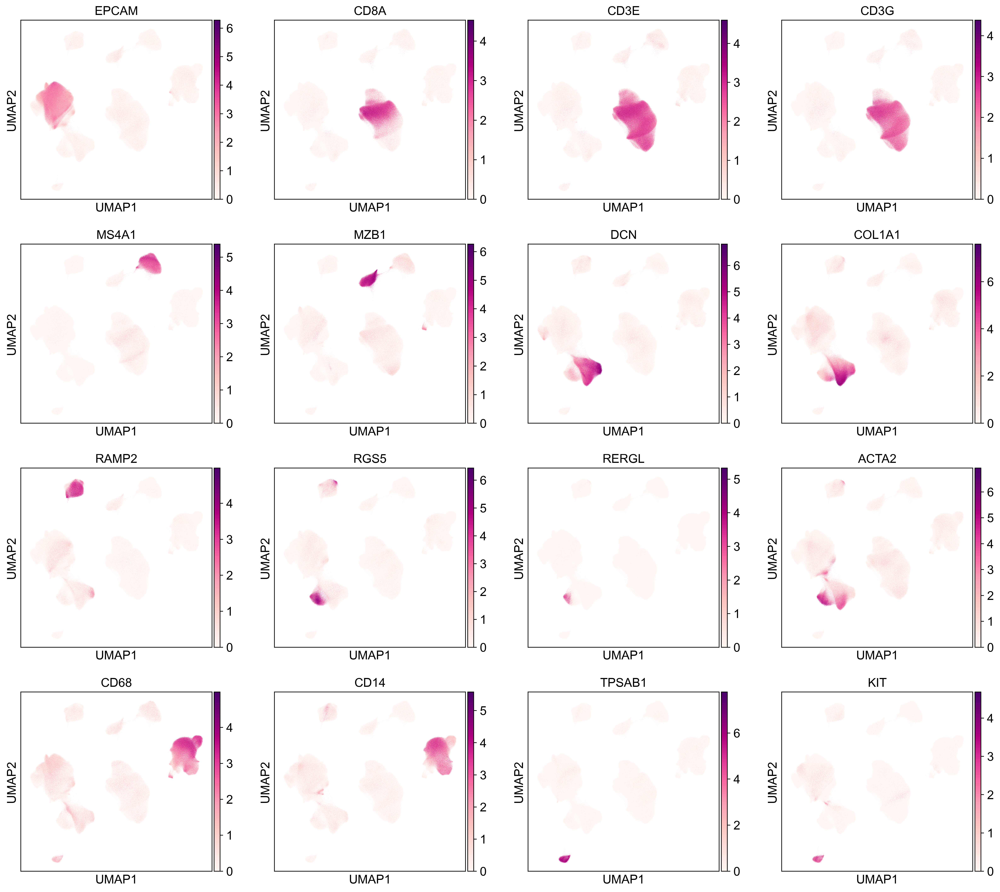

In [5]:
sc.pl.umap(adata,color=['EPCAM', # Epithelial
                        'CD8A','CD3E','CD3G', #T cell
                        'MS4A1', #B cell
                        'MZB1', #Plasma
                        'DCN','COL1A1', #Fibroblast
                        'RAMP2',#EC
                        'RGS5', #Pericyte
                        'RERGL','ACTA2', #SMC
                        'CD68', #Macrophage
                        'CD14', #Monocyte
                        'TPSAB1','KIT', #Mast
                        ],
                        ncols=4)

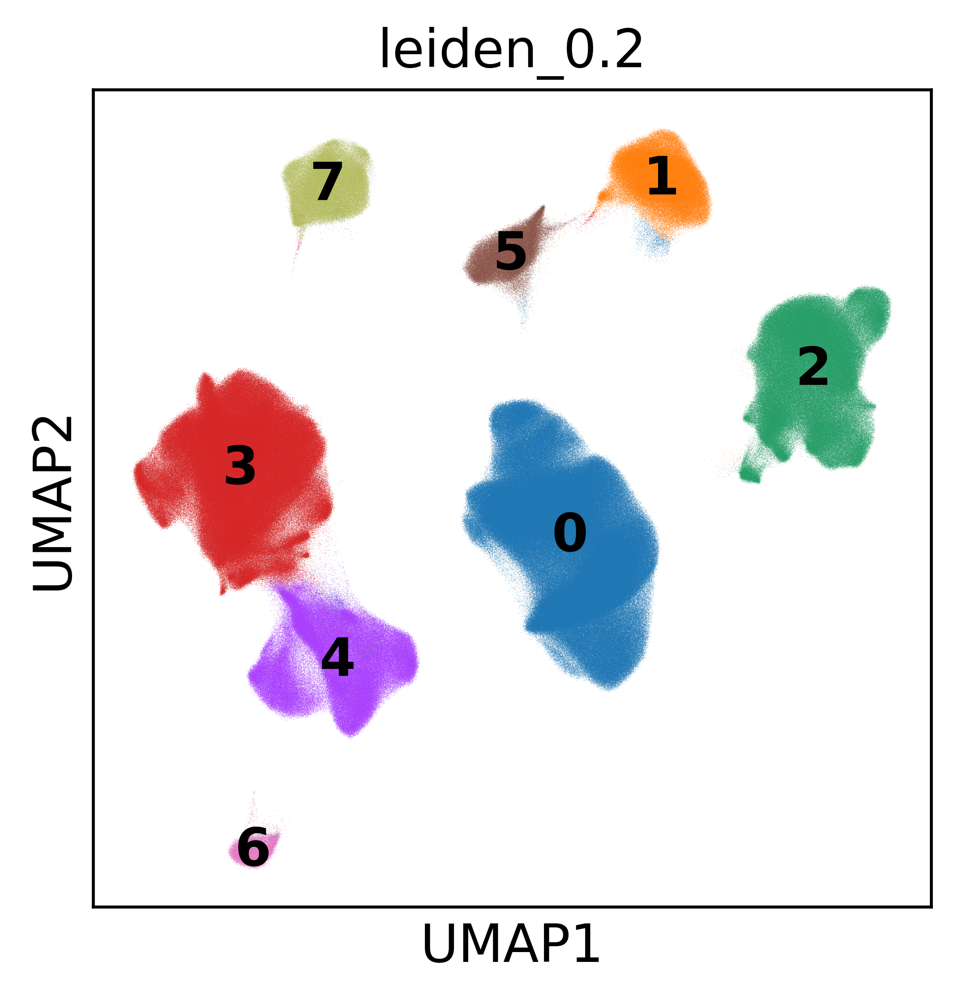

In [6]:
sc.pl.umap(adata,color='leiden_0.2',legend_loc='on data')

In [7]:
# Define the mapping of leiden_0.2 values
leiden_mapping = {
    '0': 'T cell',
    '1': 'B cell',
    '2': 'Myeloid',
    '3': 'Epithelium',
    '4': 'Stromal',
    '5': 'Plasma',
    '6': 'Mast',
    '7': 'Endothelium'
}

# Apply the mapping to change the values
adata.obs['leiden_0.2_anno'] = adata.obs['leiden_0.2'].replace(leiden_mapping)

/tmp/ipykernel_3738381/3234024451.py:14: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  adata.obs['leiden_0.2_anno'] = adata.obs['leiden_0.2'].replace(leiden_mapping)


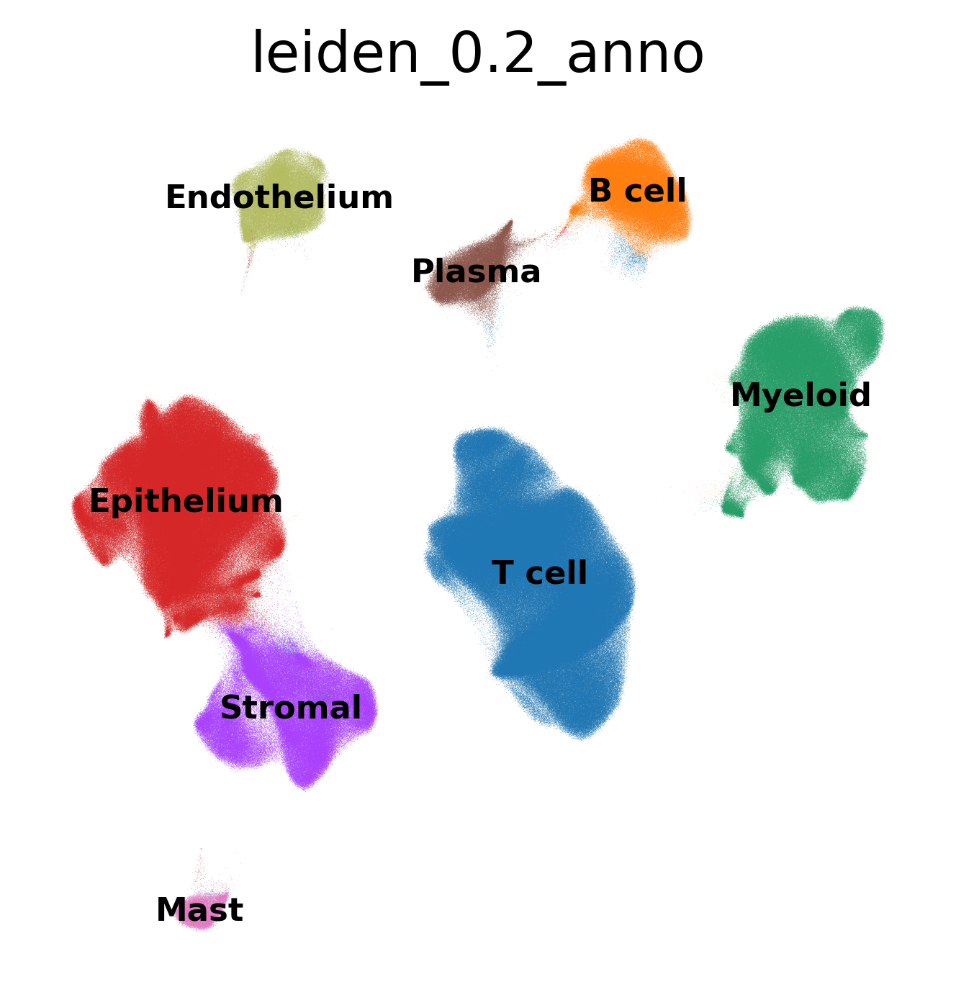

In [8]:
sc.pl.umap(adata,color='leiden_0.2_anno',legend_loc='on data',
           legend_fontsize='xx-small',frameon=False)

In [ ]:
#split_by_celltype_for_subclustering

In [ ]:
#EC

In [9]:
ec=adata[adata.obs['leiden_0.2']=='7']
ec.write_h5ad('/path/to/h5ad_raw/concat_data/07_ec.h5ad')

/opt/anaconda/envs/ahwodn_2/lib/python3.10/site-packages/anndata/_core/anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/opt/anaconda/envs/ahwodn_2/lib/python3.10/site-packages/anndata/_core/anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/opt/anaconda/envs/ahwodn_2/lib/python3.10/site-packages/anndata/_core/anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


In [ ]:
# Epithelial

In [10]:
epi=adata[adata.obs['leiden_0.2']=='3']
epi.write_h5ad('/path/to/h5ad_raw/concat_data/07_epi.h5ad')

/opt/anaconda/envs/ahwodn_2/lib/python3.10/site-packages/anndata/_core/anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/opt/anaconda/envs/ahwodn_2/lib/python3.10/site-packages/anndata/_core/anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/opt/anaconda/envs/ahwodn_2/lib/python3.10/site-packages/anndata/_core/anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


In [ ]:
#B cell

In [11]:
b=adata[adata.obs['leiden_0.2'].isin(['1','5'])]
b.write_h5ad('/path/to/h5ad_raw/concat_data/07_bcell.h5ad')

/opt/anaconda/envs/ahwodn_2/lib/python3.10/site-packages/anndata/_core/anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/opt/anaconda/envs/ahwodn_2/lib/python3.10/site-packages/anndata/_core/anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/opt/anaconda/envs/ahwodn_2/lib/python3.10/site-packages/anndata/_core/anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


In [ ]:
#Myeloid

In [12]:
mye=adata[adata.obs['leiden_0.2']=='2']
mye.write_h5ad('/path/to/h5ad_raw/concat_data/07_mye.h5ad')

/opt/anaconda/envs/ahwodn_2/lib/python3.10/site-packages/anndata/_core/anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/opt/anaconda/envs/ahwodn_2/lib/python3.10/site-packages/anndata/_core/anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


In [ ]:
#Fibor+Mural

In [13]:
fibro_mural=adata[adata.obs['leiden_0.2']=='4']
fibro_mural.write_h5ad('/path/to/h5ad_raw/concat_data/07_fibro+mural.h5ad')

/opt/anaconda/envs/ahwodn_2/lib/python3.10/site-packages/anndata/_core/anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/opt/anaconda/envs/ahwodn_2/lib/python3.10/site-packages/anndata/_core/anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


In [ ]:
#T cell

In [14]:
tcell=adata[adata.obs['leiden_0.2']=='0']
tcell.write_h5ad('/path/to/h5ad_raw/concat_data/07_tcell.h5ad')

/opt/anaconda/envs/ahwodn_2/lib/python3.10/site-packages/anndata/_core/anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/opt/anaconda/envs/ahwodn_2/lib/python3.10/site-packages/anndata/_core/anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/opt/anaconda/envs/ahwodn_2/lib/python3.10/site-packages/anndata/_core/anndata.py:1301: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


In [ ]:
del adata.obs['leiden_0.2']

In [ ]:
adata.write_h5ad('/path/to/h5ad_annotated/_sc_ALL.h5ad')